
# Analysis of nucleic acid trajectories

Thor van Heesch (T.vanHeesch@uva.nl) and Jocelyne Vreede (J.Vreede@uva.nl)

van 't Hoff Institute for Molecular Sciences, University of Amsterdam

===

The code in this tutorial is based on `MDNA`, using rigid body representations for base pairs. 

To go through the tutorial, run each cell with code, using either shift-enter or the play button. 

This notebook will demonstrate different techniques to analyze DNA structures and trajectory data. You'll learn to
- Extract and analyze different structural parameters.
- Visualize these parameters to understand double stranded nucleic acid behavior.


### A disclaimer 

The mdna software contains experimental code developed by Jocelyne’s research group. This code facilitates the analysis and generation of DNA structures and ensembles. If anything is unclear or does not work as expected, do not feel discouraged. Instead, please reach out, and we are happy to help! In principle, you do not have to read up on mdna. However, if you are curious, feel free to explore its contents: 

[Documentation](https://heezch.github.io/mdna/)

[Publication](https://academic.oup.com/nar/article/54/10/gkag549/8699744)

Start with importing required libraries, by running the cell (shift-enter, or the 'play' button). The brackets next to the cell will change from [] to [*] (running) to [1] (done). The number in the brackets indicates the order in which you executed cells. 

In [1]:
# The solutions are in the solutions/ folder: run them from the main folder, where data/ and devtools/ are
import os
if os.path.basename(os.getcwd()) == 'solutions':
    os.chdir('..')

In [2]:
#import libraries
import numpy as np
import mdtraj as md
import matplotlib.pyplot as plt
import seaborn as sns

import devtools.mdna_workarounds  # fixes for known issues in mdna 0.2.0, see devtools/mdna_workarounds.py
import mdna
from devtools.viewer import view  # 3D viewer inside the notebook, see devtools/viewer.py

## Load molecular dynamics data

For this tutorial, you will use data from a molecular dynamics simulation of DNA and RNA. Let's start with DNA. 

Visualize the trajectory. You can use either VMD, pymol or molstar. 

VMD: File -> New Molecule... and select `dna.pdb`. Then, File -> Load data into molecule and select `dna.xtc`. 

Pymol: File -> Open, and select `dna.pdb` and `dna.xtc`. 

[molstar.org/viewer: ](https://molstar.org/viewer/) In the menu on the left, select Load Trajectory, then select `dna.pdb` for the Model and `dna.xtc` for the Coordinates. 

Now load the trajectory as an mdtraj object, and then convert the data to an `mdna` object. Now you can extract the sequence.

`view(traj)` shows the trajectory in 3D, inside the notebook. How to use it:

- **Rotate:** drag with the left mouse button. **Pan:** drag with the right mouse button. **Zoom:** scroll.
- **Play:** the trajectory has many frames, so it plays as a movie. Use the play button in the viewer to start and pause it.
- Long trajectories are thinned to about 100 frames, and the cell above the viewer tells you the stride.
- Water and ions are hidden, so you see only the DNA.

The viewer loads Mol* from the internet, so you need a connection.

In [3]:
#load a trajectory
traj = md.load('./data/dna.xtc', top='./data/dna.pdb')

# Load the trajectory
dna = mdna.load(traj)
dna.describe()

# Look at the trajectory in 3D
view(traj)

DNA structure with 30 base pairs
Sequence: TTGGCCCGCTGGTCGCCGCTATCGACAGGC
Trajectory: <mdtraj.Trajectory with 201 frames, 1897 atoms, 60 residues, and unitcells>
Frames:  (30, 201, 4, 3)
Showing 1 of every 3 frames (67 frames).


<IPython.core.display.Javascript object>

### Questions

a. What is the sequence of the DNA in the provided data?

b. How many frames does the trajectory contain?

c. Visualize the first frame of the provided simulation data. 

**Answers**

a. `TTGGCCCGCTGGTCGCCGCTATCGACAGGC`, 30 base pairs. `dna.describe()` prints it.

b. 201 frames: see `Trajectory: <mdtraj.Trajectory with 201 frames ...>`, or the second number in `Frames: (30, 201, 4, 3)`.

c. In the notebook, use `view(traj[0])`. In a viewer, load `dna.pdb` and `dna.xtc` and go to the first frame.

In [4]:
view(traj[0])

<IPython.core.display.Javascript object>

## Extracting and Visualizing Rigid Base Parameters
Here you will extract and plot the rigid base parameters. 

First extract the mean reference frames for each base pair. Also extract the base reference frames.  

In [5]:
# Extract mean reference frames 
mean_frames = dna.get_frames()
print(mean_frames.shape)

#plot the mean reference frames
#dna.draw(backbone=True, triads=True, length=0.75)

#Extract base reference frames
base_frames = dna.get_base_frames()

(30, 201, 4, 3)


In [6]:
# Extract and visualize parameters
base, names = dna.get_parameters(base=True)
print(base.shape, names)

step, names = dna.get_parameters(step=True)
print(step.shape, names)

params_dna, names = dna.get_parameters()
print(params_dna.shape, names)

(201, 30, 6) ['shear', 'stretch', 'stagger', 'buckle', 'propeller', 'opening']
(201, 30, 6) ['shift', 'slide', 'rise', 'tilt', 'roll', 'twist']
(201, 30, 12) ['shear', 'stretch', 'stagger', 'buckle', 'propeller', 'opening', 'shift', 'slide', 'rise', 'tilt', 'roll', 'twist']


You can also extract a single parameter and make a plot. Below code is provided as a function to plot the parameters. If you want to plot another parameter, you only need to change `name` in the cell below the definition of the plot function `plot_parameters()`. To draw a parameter in one panel of a larger figure, pass that panel as `ax`.

In [7]:
def plot_parameters(obj, name, ax=None, color='tab:orange'): 
    para = obj.get_parameter(name)
    if ax is None:
        fig, ax = plt.subplots(figsize=[5,3])
    mean = np.mean(para, axis=0)
    std = np.std(para, axis=0)
    x = range(len(mean))

    ax.fill_between(x, mean-std, mean+std, color=color, alpha=0.2)
    ax.plot(mean, color=color, lw=1)    
    ax.scatter(x=x, y=mean, color=color, s=10)
    ax.set_title(name)
    # r'$\mathrm{\AA}$' is how matplotlib writes the Ångström symbol
    unit = r'$\mathrm{\AA}$' if name in ['shift', 'slide', 'rise', 'shear', 'stretch', 'stagger'] else 'degrees'
    ax.set_ylabel(f'{name} [{unit}]')
    ax.set_xlabel('Base pair step')
    base_map = obj.base_pair_map
    anti_sequence = [base_map[c] for c in obj.sequence]
    base_pairs = [f'{i}-{j}' for i, j in zip(obj.sequence, anti_sequence)]
    ticks = list(range(0, len(base_pairs)))
    _ = ax.set_xticks(ticks, base_pairs, rotation=45)

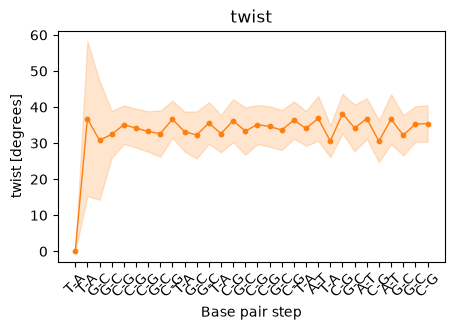

In [8]:
name = 'twist'
plot_parameters(dna, name)

### Questions

a. Plot all base parameters and all step parameters per base pair step. 

b. Some parameters are given in Å and others in degrees. Which ones, and why?

c. Why does the first base pair have values of 0 for all step parameters?

d. Choose one base or step parameter and describe whether the type of base pair may affect it. 

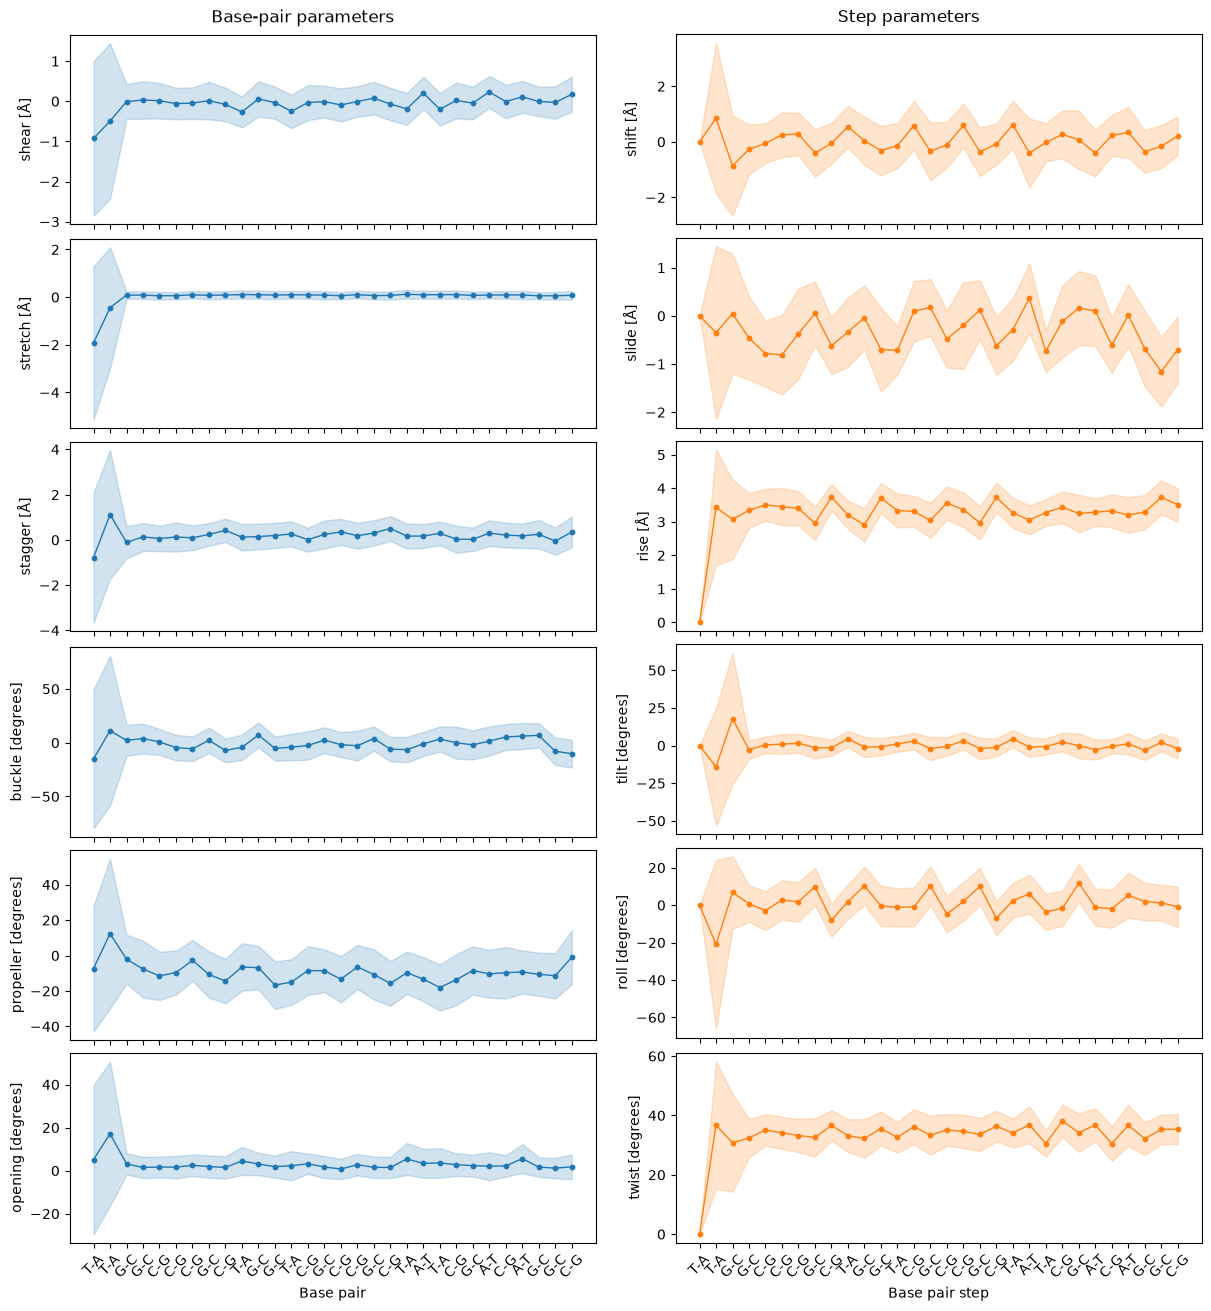

In [9]:
# a. All parameters in one figure. Each row pairs a base-pair parameter with the step parameter
# that describes the same motion between neighbouring base pairs (shear and shift, ..., opening and twist).
def plot_all_parameters(obj):
    fig = plt.figure(figsize=[12, 13], layout='constrained')
    groups = [('Base-pair parameters', ['shear', 'stretch', 'stagger', 'buckle', 'propeller', 'opening'], 'tab:blue'),
              ('Step parameters', ['shift', 'slide', 'rise', 'tilt', 'roll', 'twist'], 'tab:orange')]
    for column, (title, group, color) in zip(fig.subfigures(1, 2), groups):
        column.suptitle(title)
        axes = column.subplots(len(group), 1, sharex=True)
        for ax, name in zip(axes, group):
            plot_parameters(obj, name, ax=ax, color=color)
            ax.set_title('')
            ax.set_xlabel('')
        axes[-1].set_xlabel('Base pair' if title.startswith('Base') else 'Base pair step')

plot_all_parameters(dna)

**Answers**

a. See the figure above.

b. The translational parameters are distances, in Å: shear, stretch and stagger (base pair) and shift, slide and rise (step). The rotational parameters are angles, in degrees: buckle, propeller and opening (base pair) and tilt, roll and twist (step).

c. A step parameter describes how a base pair sits relative to the previous base pair. The first base pair has no previous base pair, so mdna fills this position with zeros.

d. Two examples, away from the frayed ends of the duplex:
- Opening: A-T pairs open more than G-C pairs (on average 3.8 vs 2.1 degrees) and fluctuate more (standard deviation 6.9 vs 5.0 degrees). An A-T pair has two hydrogen bonds, a G-C pair three.
- Roll: pyrimidine-purine steps (CpG, CpA, TpG, TpA) have a larger roll (about +9 degrees) than purine-pyrimidine steps (about -4 degrees). Pyrimidine-purine steps are the most flexible steps in DNA.

The base pairs at both ends fluctuate most of all: the ends of the duplex fray.

## RNA

There is also a trajectory of double stranded RNA, in `data/rna.pdb` and `data/rna.xtc`. 

### Questions

a. What is the sequence of the RNA in the provided data?

b. How many frames does the trajectory contain?

c. Visualize the first frame of the provided simulation data. 

d. Plot all base parameters and all step parameters per base pair step. 

e. Choose one base or step parameter and describe whether the type of base pair may affect it. 

f. Which parameters differ from the DNA trajectory? 

In [10]:
#load the trajectory
traj = md.load('./data/rna.xtc', top='./data/rna.pdb')

# convert to mdna object
rna = mdna.load(traj)
rna.describe()

# Extract mean reference frames 
rna_mean_frames = rna.get_frames()
print(rna_mean_frames.shape)

#plot the mean reference frames
#rna.draw(backbone=True, triads=True, length=0.75)

#Extract base reference frames
base_frames = rna.get_base_frames()

# Extract and visualize parameters
base, names = rna.get_parameters(base=True)
print(base.shape, names)

rna_step, names = rna.get_parameters(step=True)
print(rna_step.shape, names)

params_rna, names = rna.get_parameters()
print(params_rna.shape, names)

RNA structure with 20 base pairs
Sequence: UAUGUACGACUGAAGCGAUU
Trajectory: <mdtraj.Trajectory with 201 frames, 1274 atoms, 40 residues, and unitcells>
Frames:  (20, 201, 4, 3)
(20, 201, 4, 3)


(201, 20, 6) ['shear', 'stretch', 'stagger', 'buckle', 'propeller', 'opening']
(201, 20, 6) ['shift', 'slide', 'rise', 'tilt', 'roll', 'twist']
(201, 20, 12) ['shear', 'stretch', 'stagger', 'buckle', 'propeller', 'opening', 'shift', 'slide', 'rise', 'tilt', 'roll', 'twist']


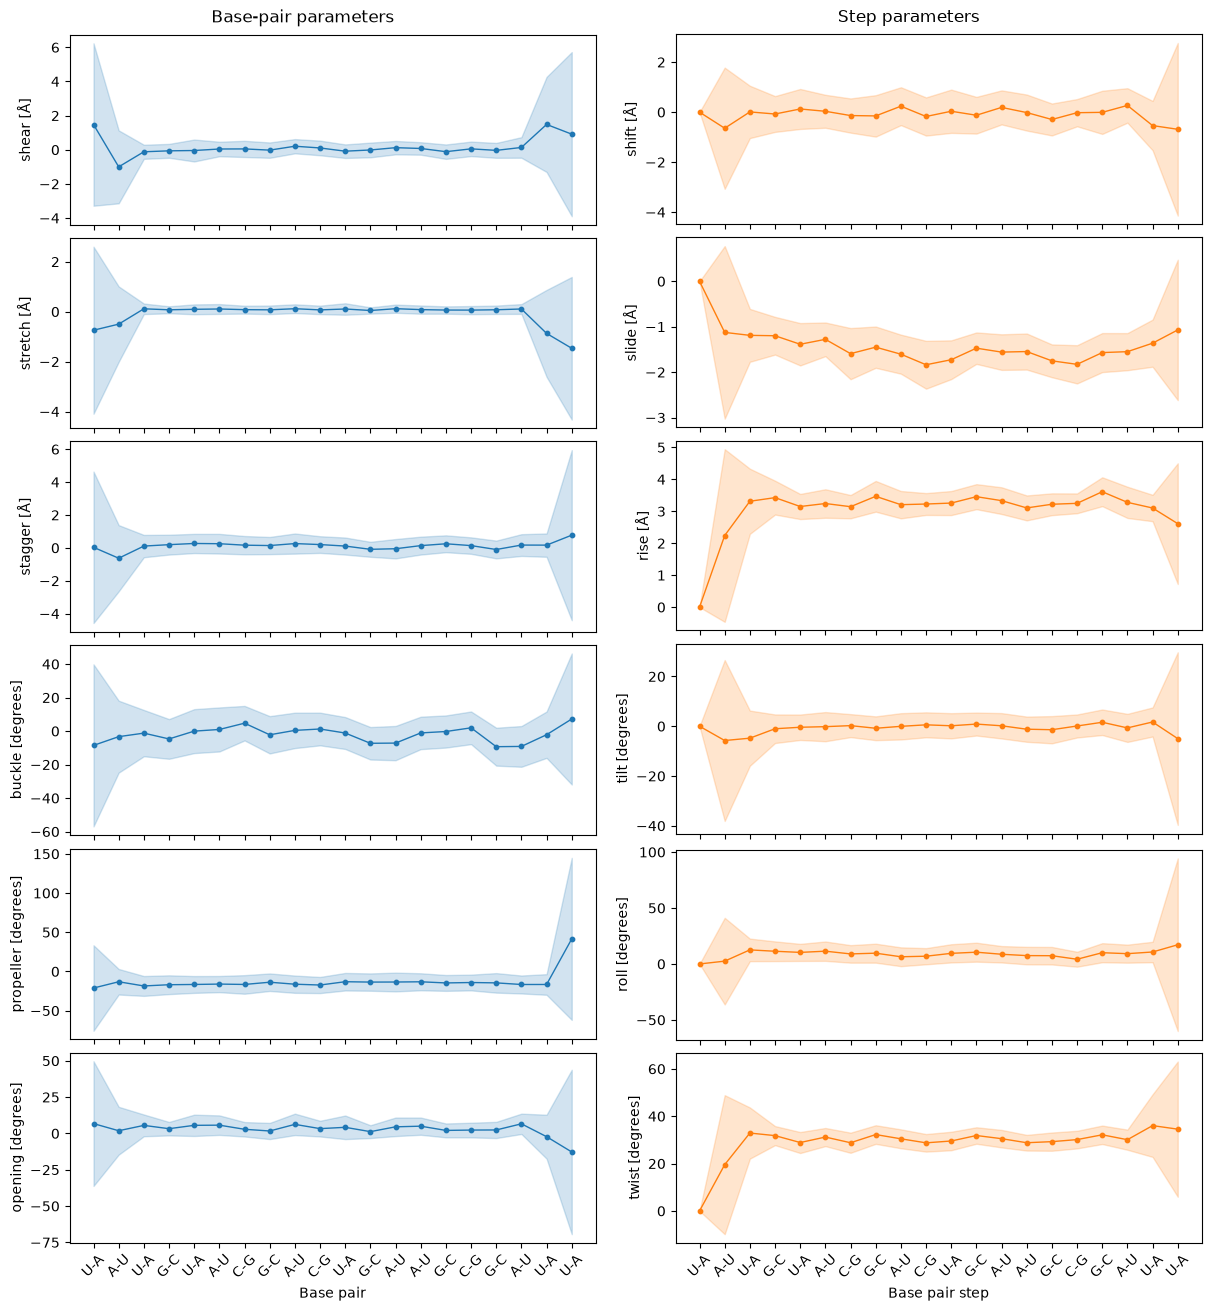

In [11]:
plot_all_parameters(rna)

**Answers**

a. `UAUGUACGACUGAAGCGAUU`, 20 base pairs.

b. 201 frames.

c. `view(traj[0])`, or load `rna.pdb` and `rna.xtc` in a viewer.

d. See the figure above.

e. As in DNA, A-U pairs open more than G-C pairs (on average 5.4 vs 2.4 degrees).

f. Double-stranded RNA forms an A-form helix, DNA a B-form helix. Compared to the DNA trajectory (averages over the inner base pairs):

| parameter | DNA | RNA |
|---|---|---|
| slide | -0.3 Å | -1.5 Å |
| roll | 1.9° | 9.0° |
| twist | 34.2° (10.5 bp per turn) | 30.5° (11.8 bp per turn) |
| propeller | -10° | -15° |
| rise | 3.3 Å | 3.3 Å |

The rise per step is about the same. The A-form helix is still shorter per base pair along its axis, because the base pairs are tilted and pushed away from the helix axis. The distributions below show the same differences.

## Advanced Visualization of Rigid Base Parameters
Use statistical visualization to understand distributions of rigid base parameters. Below, code is provided for the visualization of the rigid base parameters as probability distributions, first for the DNA data and then for the RNA data. 

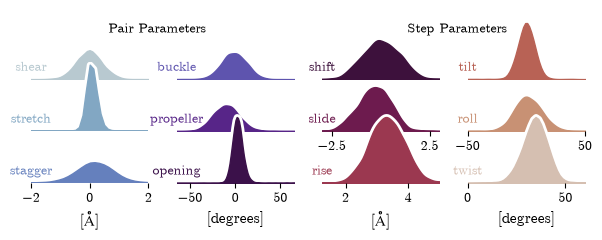

In [12]:
# Example on how to plot KDE's of all parameters
import matplotlib as mpl, matplotlib.font_manager as font_manager
import seaborn as sns
mpl.rcParams['font.family'] = 'serif'
cmfont = font_manager.FontProperties(fname=mpl.get_data_path() + '/fonts/ttf/cmr10.ttf')
mpl.rcParams['font.serif'] = cmfont.get_name()
mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['axes.formatter.use_mathtext'] = True

colors = sns.color_palette('twilight', 12)
lims = [(-2,2), (-2,2), (-2,2), (-65,65), (-65,65), (-65,65)] + [(-3,3), (-3,3), (1.25,5), (-50,50), (-50,50), (0,60)]
def plot_kde(params):
    fig, ax = plt.subplots(3, 4, figsize=(6, 2.5), sharey='col')
    # ax = ax.flatten()
    idx, jdx = 0, 0
    for _, name in enumerate(names):
        para = params[:, 1:, names.index(name)]
        sns.kdeplot(para.flatten(), ax=ax[idx][jdx], fill=True, color='white', lw=5)  # density=True
        sns.kdeplot(para.flatten(), ax=ax[idx][jdx], fill=True, color=colors[_], alpha=1, lw=1)  # density=True
        ax[idx][jdx].set_title(name, x=0, y=0, color=colors[_], fontsize=10)
        ax[idx][jdx].set_xlim(lims[_])

        ax[idx][jdx].set_facecolor('none')
        ax[idx][jdx].set_yticklabels([])
        ax[idx][jdx].set_yticks([])
        ax[idx][jdx].set_ylabel('')
        if name in ['shear', 'buckle', 'shift', 'tilt', 'stretch', 'propeller']:
            ax[idx][jdx].set_xticks([])
        idx += 1
        if idx == 3:
            idx = 0
            jdx += 1
        if jdx == 4:
            jdx = 0

        if idx == 0 and jdx in [0, 1, 2, 3]:
            ax[idx][jdx].set_xticklabels([])
        if idx == 1 and jdx in [0, 1]:
            ax[idx][jdx].set_xticklabels([])

    ax[-1][0].set_xlabel(r'[$\mathrm{\AA}$]', fontsize=11)
    ax[-1][1].set_xlabel('[degrees]', fontsize=11)
    ax[-1][2].set_xlabel(r'[$\mathrm{\AA}$]', fontsize=11)
    ax[-1][3].set_xlabel('[degrees]', fontsize=11)
    fig.tight_layout()
    fig.subplots_adjust(hspace=-.25)

    sns.despine(bottom=True, left=True)
    fig.text(0.25, 0.85, 'Pair Parameters', ha='center', fontsize=10)
    fig.text(0.75, 0.85, 'Step Parameters', ha='center', fontsize=10)

plot_kde(params_dna)


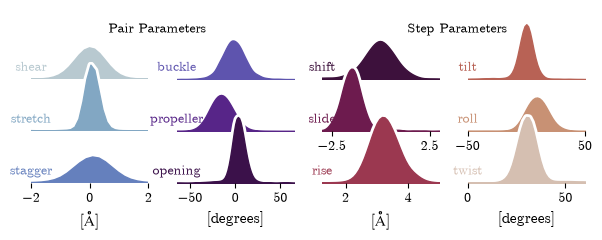

In [13]:
plot_kde(params_rna)
